Upload colon_cancer.csv (original)


Saving colon_cancer.csv to colon_cancer.csv

Upload colon_cancer_extended.csv


Saving colon_cancer_extended.csv to colon_cancer_extended.csv


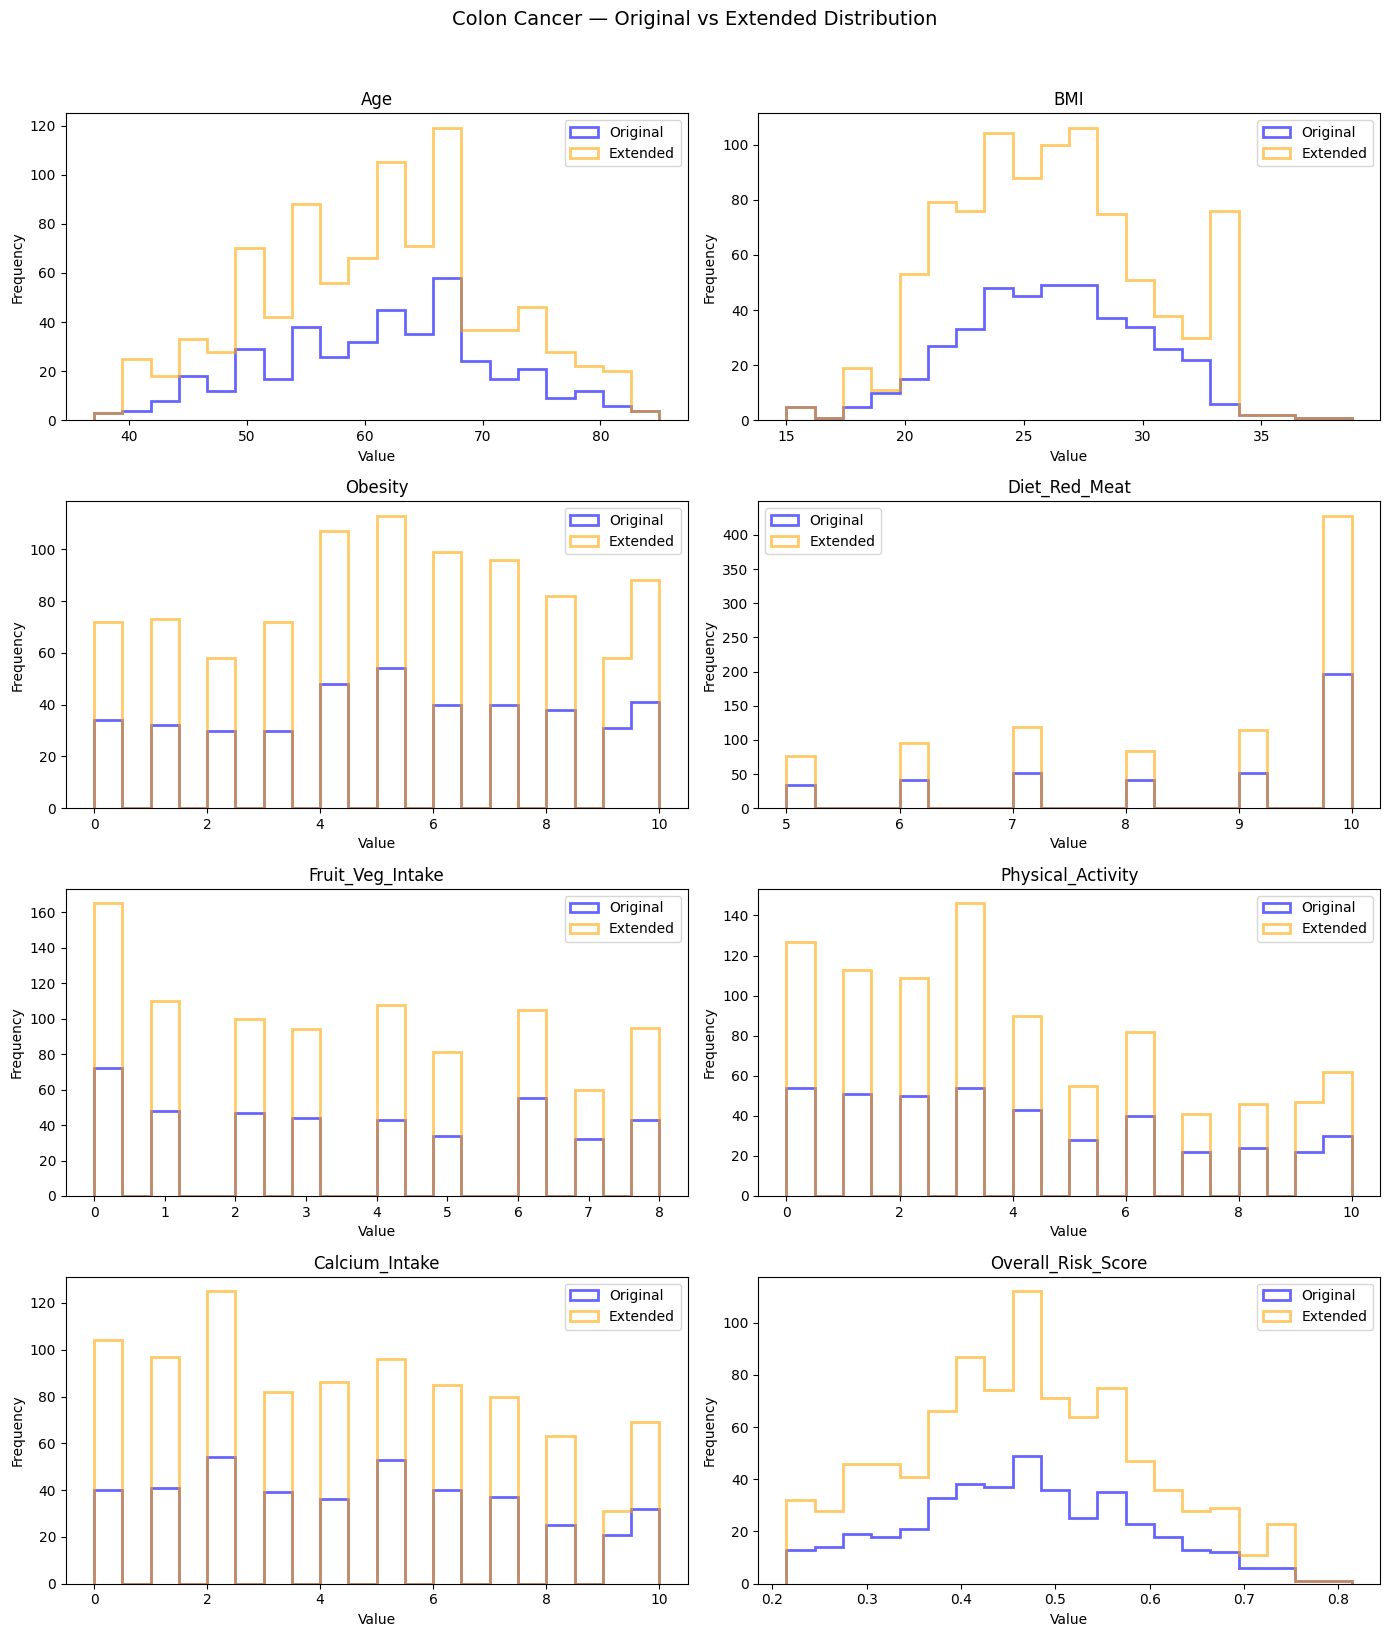

Saved colon_histogram_comparison.png

STATISTICAL COMPARISON: Original vs Extended

--- Age ---
Stat             Original     Extended
------------------------------------
mean               61.443       60.991
std                 9.710        9.886
min                37.000       37.000
25%                54.250       54.000
50%                62.000       61.000
75%                68.000       68.000
max                85.000       85.000

--- BMI ---
Stat             Original     Extended
------------------------------------
mean               26.178       26.150
std                 3.903        4.170
min                15.000       15.000
25%                23.525       23.100
50%                26.300       26.100
75%                29.000       28.900
max                38.800       38.800

--- Obesity ---
Stat             Original     Extended
------------------------------------
mean                5.160        5.144
std                 3.039        2.993
min                 0.

In [ ]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ks_2samp

# Upload files
print("Upload colon_cancer.csv (original)")
uploaded = files.upload()
df_original = pd.read_csv("colon_cancer.csv")

print("\nUpload colon_cancer_extended.csv")
uploaded = files.upload()
df_extended = pd.read_csv("colon_cancer_extended.csv")

# Numeric columns to compare
num_cols = [
    "Age", "BMI", "Obesity", "Diet_Red_Meat",
    "Fruit_Veg_Intake", "Physical_Activity",
    "Calcium_Intake", "Overall_Risk_Score"
]

# Plot histograms
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df_original[col], alpha=0.6,
                 color='blue',   label='Original',
                 histtype='step', bins=20, linewidth=2)
    axes[i].hist(df_extended[col], alpha=0.6,
                 color='orange', label='Extended',
                 histtype='step', bins=20, linewidth=2)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

plt.suptitle("Colon Cancer — Original vs Extended Distribution",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("colon_histogram_comparison.png",
            bbox_inches='tight', dpi=150)
plt.show()
print("Saved colon_histogram_comparison.png")

# Statistical comparison
print("\n" + "=" * 60)
print("STATISTICAL COMPARISON: Original vs Extended")
print("=" * 60)

for col in num_cols:
    print(f"\n--- {col} ---")
    print(f"{'Stat':<12} {'Original':>12} {'Extended':>12}")
    print("-" * 36)
    orig_desc = df_original[col].describe()
    ext_desc  = df_extended[col].describe()
    for stat in ['mean', 'std', 'min', '25%', '50%', '75%', 'max']:
        print(f"{stat:<12} {orig_desc[stat]:>12.3f} {ext_desc[stat]:>12.3f}")

# KS Test
print("\n" + "=" * 60)
print("KS TEST (p > 0.05 = similar distributions)")
print("=" * 60)

for col in num_cols:
    stat, p = ks_2samp(df_original[col], df_extended[col])
    status = "✓ similar" if p > 0.05 else "✗ different"
    print(f"{col:<25} p={p:.4f}  {status}")

In [ ]:
# Check correlation between Overall_Risk_Score and Risk_Level
print(df_original.groupby("Risk_Level")["Overall_Risk_Score"].describe())

            count      mean       std       min       25%       50%       75%  \
Risk_Level                                                                      
High         29.0  0.702109  0.036802  0.662771  0.675543  0.688493  0.724642   
Low          59.0  0.273770  0.032589  0.215081  0.246806  0.277972  0.300570   
Medium      330.0  0.479737  0.083105  0.330512  0.412651  0.471797  0.547934   

                 max  
Risk_Level            
High        0.814066  
Low         0.329361  
Medium      0.656158  


In [ ]:
!pip install xgboost
!pip install lightgbm
!pip install catboost

Upload colon_cancer_extended.csv


Saving colon_cancer_extended.csv to colon_cancer_extended (2).csv
Loaded: (918, 11)
Risk_Level
Medium    731
Low       108
High       79
Name: count, dtype: int64
✅ Logistic Regression | Accuracy: 0.3783
✅ Decision Tree | Accuracy: 0.6304
✅ Random Forest | Accuracy: 0.7652
✅ Extra Trees | Accuracy: 0.7652
✅ AdaBoost | Accuracy: 0.7696
✅ Gradient Boosting | Accuracy: 0.7522
✅ SVM (RBF Kernel) | Accuracy: 0.5000
✅ XGBoost | Accuracy: 0.7217
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000061 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 224
[LightGBM] [Info] Number of data points in the train set: 688, number of used features: 9
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with po

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


✅ LightGBM | Accuracy: 0.7348
✅ CatBoost | Accuracy: 0.7522

📊 Colon Cancer Model Performance:
                 Model  Accuracy
4             AdaBoost  0.769565
2        Random Forest  0.765217
3          Extra Trees  0.765217
5    Gradient Boosting  0.752174
9             CatBoost  0.752174
8             LightGBM  0.734783
7              XGBoost  0.721739
1        Decision Tree  0.630435
6     SVM (RBF Kernel)  0.500000
0  Logistic Regression  0.378261


/tmp/ipykernel_19634/403368181.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=results_df, palette="coolwarm")


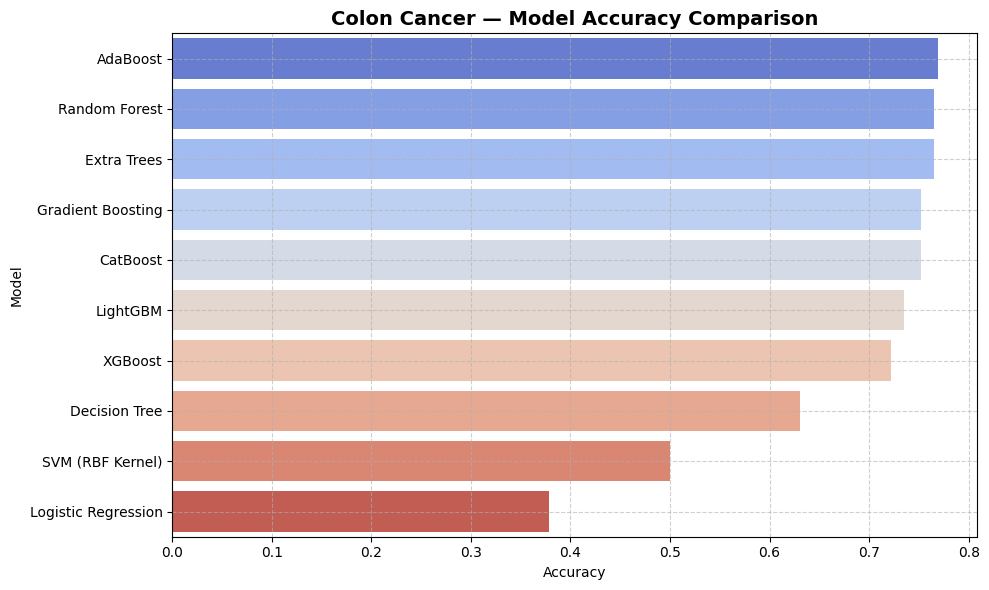


🏁 Best Model: AdaBoost
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        21
         Low       0.50      0.03      0.06        32
      Medium       0.77      0.99      0.87       177

    accuracy                           0.77       230
   macro avg       0.42      0.34      0.31       230
weighted avg       0.66      0.77      0.68       230



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, ExtraTreesClassifier)
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Upload
print("Upload colon_cancer_extended.csv")
uploaded = files.upload()
df_colon = pd.read_csv("colon_cancer_extended.csv")

print(f"Loaded: {df_colon.shape}")
print(df_colon["Risk_Level"].value_counts())

# Drop Overall_Risk_Score if present
if "Overall_Risk_Score" in df_colon.columns:
    df_colon.drop(columns=["Overall_Risk_Score"], inplace=True)

# Target and features
target_col = "Risk_Level"

# Encode target
le = LabelEncoder()
df_colon[target_col] = le.fit_transform(df_colon[target_col])

X = df_colon.drop(columns=[target_col])
y = df_colon[target_col]

# Encode categoricals
X = pd.get_dummies(X, drop_first=True)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree":       DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    "Extra Trees":         ExtraTreesClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    "AdaBoost":            AdaBoostClassifier(n_estimators=150, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=150, random_state=42),
    "SVM (RBF Kernel)":    SVC(kernel='rbf', probability=True, random_state=42, class_weight='balanced'),
    "XGBoost":             XGBClassifier(n_estimators=150, random_state=42),
    "LightGBM":            LGBMClassifier(n_estimators=150, random_state=42, class_weight='balanced'),
    "CatBoost":            CatBoostClassifier(verbose=0, random_state=42)
}

# Train and evaluate
results     = {}
predictions = {}

for name, model in models.items():
    # XGBoost needs sample_weight separately
    if name == "XGBoost":
        from sklearn.utils.class_weight import compute_sample_weight
        sw = compute_sample_weight(class_weight='balanced', y=y_train)
        model.fit(X_train, y_train, sample_weight=sw)
    else:
        model.fit(X_train, y_train)

    y_pred        = model.predict(X_test)
    acc           = accuracy_score(y_test, y_pred)
    results[name] = acc
    predictions[name] = y_pred
    print(f"✅ {name} | Accuracy: {acc:.4f}")

# Summary
results_df = pd.DataFrame(
    list(results.items()), columns=["Model", "Accuracy"]
).sort_values(by="Accuracy", ascending=False)

print("\n📊 Colon Cancer Model Performance:")
print(results_df)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette="coolwarm")
plt.title("Colon Cancer — Model Accuracy Comparison", fontsize=14, weight='bold')
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Best model detailed report
best_model_name = results_df.iloc[0]['Model']
best_preds      = predictions[best_model_name]
print(f"\n🏁 Best Model: {best_model_name}")
print(classification_report(y_test, best_preds,
                             target_names=le.classes_))

Upload cancer-risk-factors.csv


Saving cancer-risk-factors.csv to cancer-risk-factors (3).csv
Loaded: (2000, 21)
['Patient_ID', 'Cancer_Type', 'Age', 'Gender', 'Smoking', 'Alcohol_Use', 'Obesity', 'Family_History', 'Diet_Red_Meat', 'Diet_Salted_Processed', 'Fruit_Veg_Intake', 'Physical_Activity', 'Air_Pollution', 'Occupational_Hazards', 'BRCA_Mutation', 'H_Pylori_Infection', 'Calcium_Intake', 'Overall_Risk_Score', 'BMI', 'Physical_Activity_Level', 'Risk_Level']

Features: ['Age', 'Gender', 'Smoking', 'Alcohol_Use', 'Obesity', 'Family_History', 'Diet_Red_Meat', 'Diet_Salted_Processed', 'Fruit_Veg_Intake', 'Physical_Activity', 'Air_Pollution', 'Occupational_Hazards', 'BRCA_Mutation', 'H_Pylori_Infection', 'Calcium_Intake', 'BMI', 'Physical_Activity_Level']
Target:   Overall_Risk_Score
y range:  0.029 - 0.852
✅ Linear Regression | R²: 0.8213 | RMSE: 0.049659
✅ Ridge | R²: 0.8213 | RMSE: 0.049660
✅ Lasso | R²: 0.8225 | RMSE: 0.049494
✅ Decision Tree | R²: 0.2980 | RMSE: 0.098421
✅ Random Forest | R²: 0.7203 | RMSE: 0.062

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


✅ LightGBM | R²: 0.7683 | RMSE: 0.056542
✅ CatBoost | R²: 0.7897 | RMSE: 0.053875

📊 Model Performance Summary:
                Model      R2      RMSE
0               Lasso  0.8225  0.049494
1   Linear Regression  0.8213  0.049659
2               Ridge  0.8213  0.049660
3            CatBoost  0.7897  0.053875
4   Gradient Boosting  0.7886  0.054013
5            LightGBM  0.7683  0.056542
6    SVR (RBF Kernel)  0.7533  0.058348
7         Extra Trees  0.7249  0.061607
8             XGBoost  0.7226  0.061864
9       Random Forest  0.7203  0.062121
10           AdaBoost  0.7087  0.063395
11      Decision Tree  0.2980  0.098421


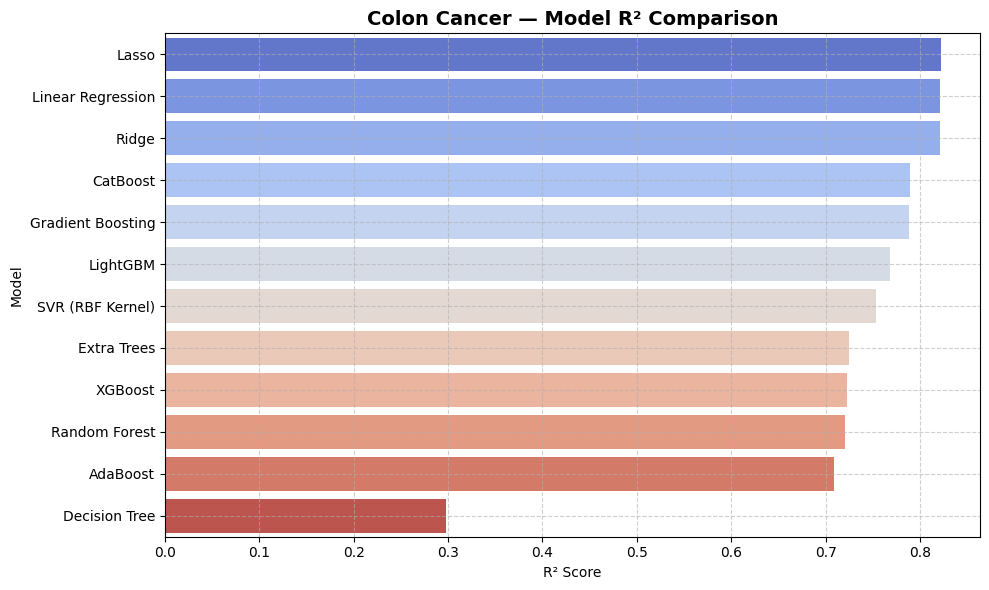

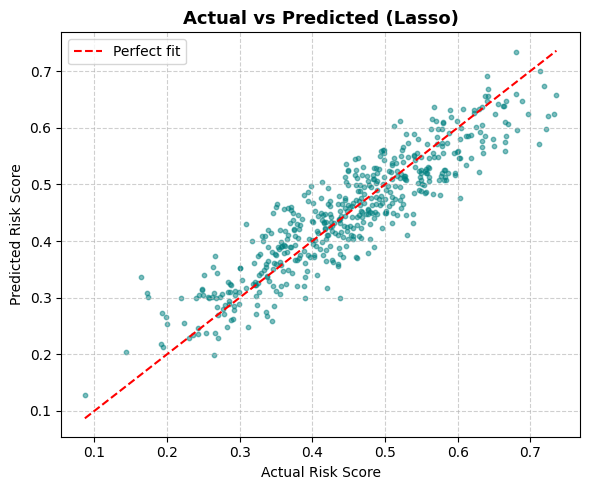

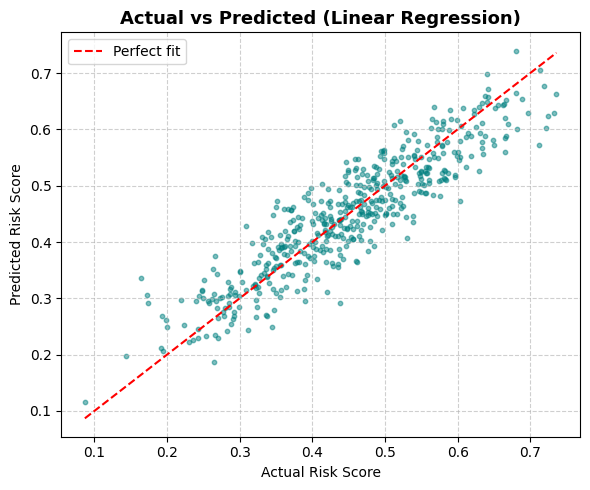

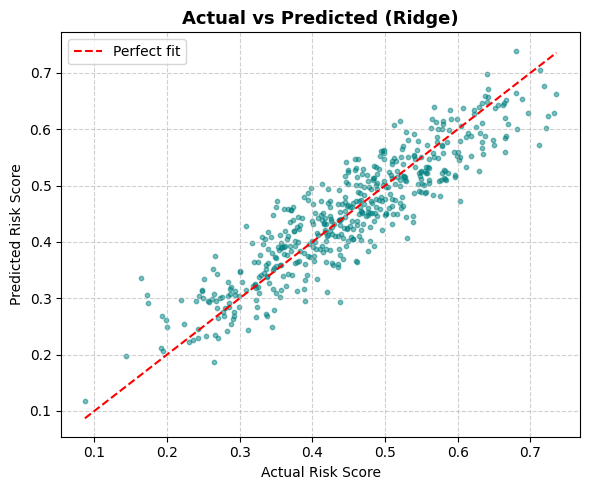


🏁 Best Model: Lasso
R²:   0.8225
RMSE: 0.049494

Predicted Risk Level Distribution:
Medium    417
Low        78
High        5
Name: count, dtype: int64


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              ExtraTreesRegressor, AdaBoostRegressor)
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# Upload
print("Upload cancer-risk-factors.csv")
uploaded = files.upload()

df_colon = pd.read_csv("cancer-risk-factors.csv")

print(f"Loaded: {df_colon.shape}")
print(df_colon.columns.tolist())

df_colon.drop(columns=[
    "Patient_ID",
    "Cancer_Type",
    "Risk_Level"
], inplace=True)

# Target = Overall_Risk_Score
target_col = "Overall_Risk_Score"

X = df_colon.drop(columns=[target_col])
y = df_colon[target_col]

print(f"\nFeatures: {X.columns.tolist()}")
print(f"Target:   {target_col}")
print(f"y range:  {y.min():.3f} - {y.max():.3f}")

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Scale
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# Regression models
models = {
    "Linear Regression":  LinearRegression(),
    "Ridge":              Ridge(alpha=1.0),
    "Lasso":              Lasso(alpha=0.001),
    "Decision Tree":      DecisionTreeRegressor(random_state=42),
    "Random Forest":      RandomForestRegressor(n_estimators=200, random_state=42),
    "Extra Trees":        ExtraTreesRegressor(n_estimators=200, random_state=42),
    "AdaBoost":           AdaBoostRegressor(n_estimators=150, random_state=42),
    "Gradient Boosting":  GradientBoostingRegressor(n_estimators=150, random_state=42),
    "SVR (RBF Kernel)":   SVR(kernel='rbf'),
    "XGBoost":            XGBRegressor(n_estimators=150, random_state=42),
    "LightGBM":           LGBMRegressor(n_estimators=150, random_state=42),
    "CatBoost":           CatBoostRegressor(verbose=0, random_state=42)
}

# Train and evaluate
results = {}
preds   = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred        = model.predict(X_test)
    r2            = r2_score(y_test, y_pred)
    rmse          = np.sqrt(mean_squared_error(y_test, y_pred))
    results[name] = {"R2": round(r2, 4), "RMSE": round(rmse, 6)}
    preds[name]   = y_pred
    print(f"✅ {name} | R²: {r2:.4f} | RMSE: {rmse:.6f}")

# Summary table
results_df = pd.DataFrame(results).T.sort_values(
    by="R2", ascending=False
).reset_index().rename(columns={"index": "Model"})

print("\n📊 Model Performance Summary:")
print(results_df)

# Plot R²
plt.figure(figsize=(10, 6))
sns.barplot(x='R2', y='Model', hue='Model',
            data=results_df, palette="coolwarm", legend=False)
plt.title("Colon Cancer — Model R² Comparison", fontsize=14, weight='bold')
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Actual vs Predicted for top 3
top_models = results_df.head(3)['Model'].tolist()

for name in top_models:
    y_pred_arr = np.array(preds[name]).flatten()
    y_test_arr = np.array(y_test).flatten()

    plt.figure(figsize=(6, 5))
    plt.scatter(y_test_arr, y_pred_arr,
                color='teal', alpha=0.5, s=10)
    plt.plot([y_test_arr.min(), y_test_arr.max()],
             [y_test_arr.min(), y_test_arr.max()],
             'r--', linewidth=1.5, label='Perfect fit')
    plt.title(f"Actual vs Predicted ({name})", fontsize=13, weight='bold')
    plt.xlabel("Actual Risk Score")
    plt.ylabel("Predicted Risk Score")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# Threshold function
def score_to_risk_level(score):
    if score < 0.330:
        return "Low"
    elif score < 0.660:
        return "Medium"
    else:
        return "High"

# Best model risk level distribution
best_model_name = results_df.iloc[0]['Model']
best_preds      = np.array(preds[best_model_name]).flatten()
risk_levels     = [score_to_risk_level(s) for s in best_preds]

print(f"\n🏁 Best Model: {best_model_name}")
print(f"R²:   {results_df.iloc[0]['R2']:.4f}")
print(f"RMSE: {results_df.iloc[0]['RMSE']:.6f}")
print(f"\nPredicted Risk Level Distribution:")
print(pd.Series(risk_levels).value_counts())

In [ ]:
# Visual Representation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# Load both
df_original = pd.read_csv("cancer-risk-factors-extended-1.csv")
df_extended = pd.read_csv("colon_cancer_extended-1.csv")

print("=== Shape ===")
print(f"Original: {df_original.shape}")
print(f"Extended: {df_extended.shape}")

# Cancer Type
print("\n=== Cancer Type Distribution ===")
print("Original:")
print(df_original["Cancer_Type"].value_counts())
print("\nExtended:")
print(df_extended["Cancer_Type"].value_counts())

# Risk Level
print("\n=== Risk Level Distribution (proportions) ===")
print("Original:")
print(df_original["Risk_Level"].value_counts(normalize=True).round(3))
print("\nExtended:")
print(df_extended["Risk_Level"].value_counts(normalize=True).round(3))

# Numeric columns
num_cols = [
    "Age", "Gender", "Smoking", "Alcohol_Use", "Obesity",
    "Family_History", "Diet_Red_Meat", "Diet_Salted_Processed",
    "Fruit_Veg_Intake", "Physical_Activity", "Air_Pollution",
    "Occupational_Hazards", "BRCA_Mutation", "H_Pylori_Infection",
    "Calcium_Intake", "Overall_Risk_Score", "BMI",
    "Physical_Activity_Level"
]

# Statistical comparison
print("\n=== Statistical Comparison ===")
print(f"{'Feature':<25} {'Orig Mean':>10} {'Ext Mean':>10} {'Orig SD':>10} {'Ext SD':>10}")
print("-" * 70)
for col in num_cols:
    print(f"{col:<25} "
          f"{df_original[col].mean():>10.3f} "
          f"{df_extended[col].mean():>10.3f} "
          f"{df_original[col].std():>10.3f} "
          f"{df_extended[col].std():>10.3f}")

# KS Test
print("\n=== KS Test (p > 0.05 = similar) ===")
for col in num_cols:
    stat, p = ks_2samp(df_original[col], df_extended[col])
    status = "✓ similar" if p > 0.05 else "✗ different"
    print(f"{col:<25} p={p:.4f}  {status}")

# Histograms
n_cols = 3
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    combined = pd.concat([df_original[col], df_extended[col]])
    bins = np.linspace(combined.min(), combined.max(), 21)

    axes[i].hist(df_original[col], bins=bins, alpha=1.0,
                 color='blue', label='Original',
                 histtype='step', linewidth=2)
    axes[i].hist(df_extended[col], bins=bins, alpha=1.0,
                 color='orange', label='Extended',
                 histtype='step', linewidth=2)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Full Dataset — Original vs Extended Distribution",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("full_dataset_comparison.png", bbox_inches='tight', dpi=150)
plt.show()
print("Saved full_dataset_comparison.png")

FileNotFoundError: [Errno 2] No such file or directory: 'colon_cancer_extended-1.csv'